In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/luckyakoko/credit-risk-prediction-data/loan_risk_prediction_dataset.csv


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
from sklearn.metrics import accuracy_score, recall_score, f1_score
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
import seaborn as sns
from xgboost import XGBClassifier

In [4]:
df = pd.read_csv("/kaggle/input/datasets/luckyakoko/credit-risk-prediction-data/loan_risk_prediction_dataset.csv")
df.shape

(5000, 10)

In [5]:
df.dropna(inplace=True)
df.isnull().sum()/len(df)*100


Age                0.0
Income             0.0
LoanAmount         0.0
CreditScore        0.0
YearsExperience    0.0
Gender             0.0
Education          0.0
City               0.0
EmploymentType     0.0
LoanApproved       0.0
dtype: float64

In [6]:
df["Income"] = df["Income"].fillna(df["Income"].mean())
df["CreditScore"] = df["CreditScore"].fillna(df["CreditScore"].mean())
df["Education"] = df["Education"].fillna(df["Education"].mode()[0])
df.skew(numeric_only=True)
df["LoanApproved"].value_counts()
df.shape

(4430, 10)

In [7]:
#Feature Engineering 
# Age Groups

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins = [18, 25, 35, 50, 65, 100],
    labels = [ "Young", "Adult", "Middle_Age", "Senior", "Retired"]
)

# Debt to Income Ratio
df["DebtToIncome"] = df["Income"] / df["LoanAmount"]

# Loan Burden Ration
df["LoanIncomeRatio"] = df["LoanAmount"] / (df["Income"] + 1)

# Career Experience 
df["ExperienceRatio"] = df["YearsExperience"] / df["Age"]
df.head()

,Age,Income,LoanAmount,CreditScore,YearsExperience,Gender,Education,City,EmploymentType,LoanApproved,AgeGroup,DebtToIncome,LoanIncomeRatio,ExperienceRatio
0,56,48353.0,31258.0,675.0,20,Female,High School,Houston,Unemployed,0,Senior,1.546900,0.646441,0.357143
1,69,57462.0,23262.0,586.0,6,Male,High School,San Francisco,Self-Employed,0,Retired,2.470209,0.404817,0.086957
2,46,44219.0,26530.0,781.0,26,Male,PhD,Houston,Self-Employed,1,Middle_Age,1.666755,0.599955,0.565217
4,60,37034.0,27871.0,500.0,19,Female,High School,Chicago,Unemployed,0,Senior,1.328765,0.752558,0.316667
5,25,47886.0,18106.0,835.0,13,Male,Masters,New York,Salaried,1,Young,2.644759,0.378098,0.520000


In [8]:
# Defining Features and the Target
X = df.drop("LoanApproved", axis=True)
y = df["LoanApproved"]

# Separate Numerical and Categorical Columns
num_cols = X.select_dtypes(include=["int64","float64"]).columns
cat_cols = X.select_dtypes(include=["object","category"]).columns

#SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
#Categorical:One-hot encode
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

print("values have been successfully encoded")


values have been successfully encoded


In [9]:
# XGBOOST CLASSIFIER MODEL

# Build Model Pipeline
model = Pipeline([
    ("preprocessing", preprocessor),
    
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=3.34,
        random_state=42,
        eval_metric="logloss"
    ))
])

# Train
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'YearsExperience',
       'DebtToIncome', 'LoanIncomeRatio', 'ExperienceRatio'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['Gender', 'Education', 'City', 'EmploymentType', 'AgeGroup'], dtype='object')...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [10]:
# Make Predictions
y_pred = model.predict(X_test)

# Predicted probabilities
y_probs = model.predict_proba(X_test)[:,1]


# Higher threshold
y_pred = (y_probs >= 0.7).astype(int)
accuracy = accuracy_score(y_test, y_pred)


print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_probs))


Accuracy: 0.9717832957110609
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       683
           1       0.95      0.92      0.94       203

    accuracy                           0.97       886
   macro avg       0.97      0.95      0.96       886
weighted avg       0.97      0.97      0.97       886

[[674   9]
 [ 16 187]]
ROC AUC: 0.9599780741296368


                         Feature  Percentage
20     EmploymentType_Unemployed       23.07
18       EmploymentType_Salaried       14.95
3                    CreditScore       13.26
19  EmploymentType_Self-Employed       12.56
1                         Income        6.74
6                LoanIncomeRatio        1.86
16                 City_New York        1.85
2                     LoanAmount        1.80
7                ExperienceRatio        1.60
5                   DebtToIncome        1.58


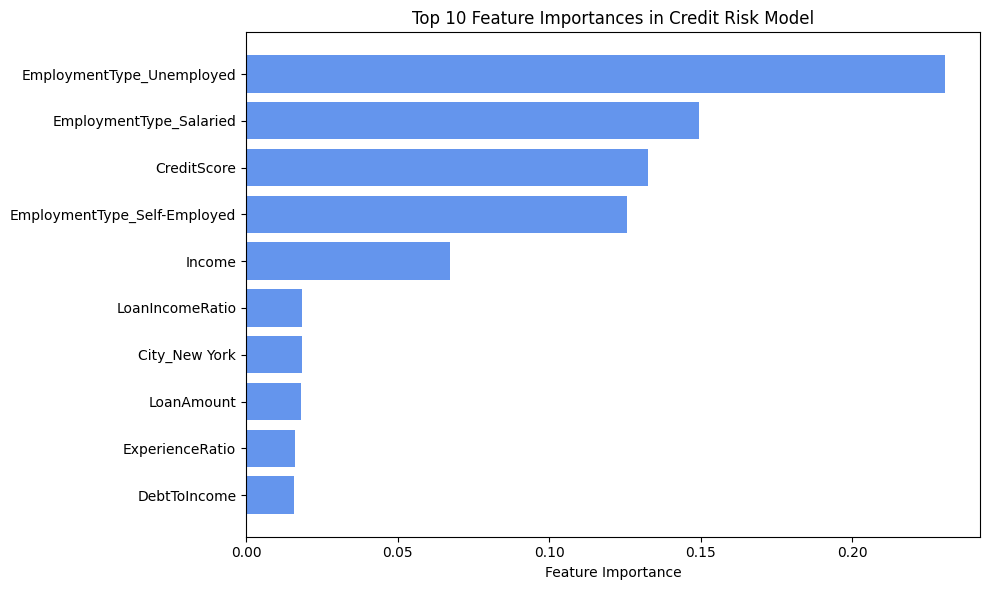

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

# Extract feature names after preprocessing (OneHotEncoder + Numerical features)
preprocessor = model.named_steps["preprocessing"]
num_features = list(preprocessor.transformers_[0][2])
cat_encoder = preprocessor.named_transformers_["cat"]
cat_features = list(cat_encoder.get_feature_names_out())
all_features = num_features + cat_features

# Get feature importances from the XGBoost classifier
importances = model.named_steps["classifier"].feature_importances_

# Create a DataFrame for visualization
feat_imp_df = pd.DataFrame({"Feature": all_features, "Importance": importances})
feat_imp_df = feat_imp_df.sort_values(by="Importance", ascending=False).head(10)

# Convert importances to percentages (rounded to 2 decimal places)
feat_imp_df["Percentage"] = (feat_imp_df["Importance"] * 100).round(2)

# Print the top 10 features with their percentages in the console
print(feat_imp_df[["Feature", "Percentage"]])

# Plot top 10 features
plt.figure(figsize=(10, 6))
plt.barh(feat_imp_df["Feature"][::-1], feat_imp_df["Importance"][::-1], color="cornflowerblue")
plt.xlabel("Feature Importance")
plt.title("Top 10 Feature Importances in Credit Risk Model")
plt.tight_layout()
plt.show()

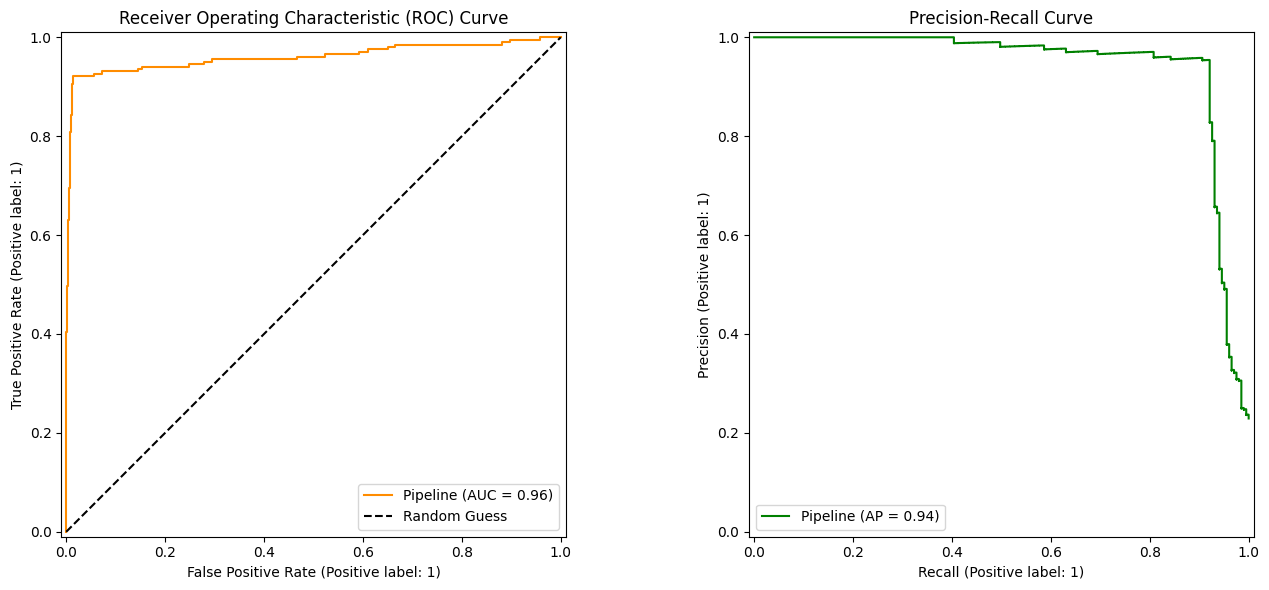

In [12]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ROC Curve
RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[0], color="darkorange")
axes[0].set_title("Receiver Operating Characteristic (ROC) Curve")
axes[0].plot([0, 1], [0, 1], "k--", label="Random Guess")
axes[0].legend()

# Precision-Recall Curve
PrecisionRecallDisplay.from_estimator(model, X_test, y_test, ax=axes[1], color="green")
axes[1].set_title("Precision-Recall Curve")

plt.tight_layout()
plt.show()

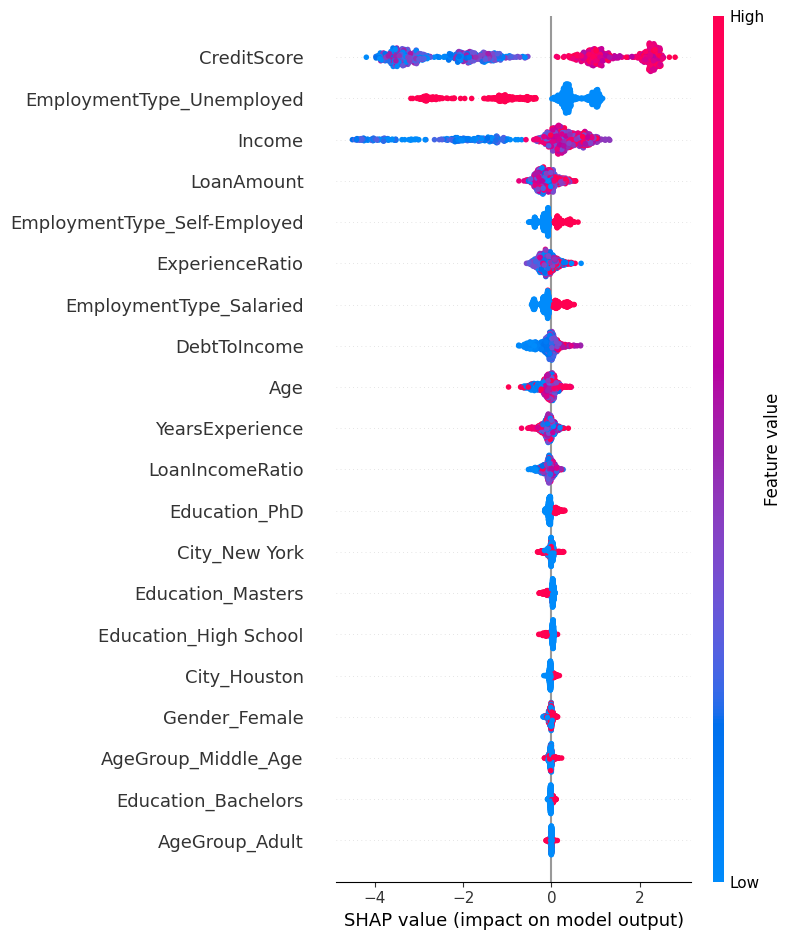

In [13]:
import shap

# Transform the test dataset using the preprocessing pipeline step
X_test_transformed = model.named_steps["preprocessing"].transform(X_test)

# Initialize the SHAP explainer with the trained XGBoost classifier
explainer = shap.TreeExplainer(model.named_steps["classifier"])
shap_values = explainer(X_test_transformed)

# Plot summary plot of feature impacts
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=all_features)

In [14]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

# Define the hyperparameter search space with the 'classifier__' prefix for the pipeline
param_distributions = {
    "classifier__max_depth": randint(3, 8),
    "classifier__learning_rate": uniform(0.01, 0.1),
    "classifier__n_estimators": randint(100, 400),
    "classifier__subsample": uniform(0.6, 0.4),
    "classifier__colsample_bytree": uniform(0.6, 0.4),
    "classifier__min_child_weight": randint(1, 6),
    "classifier__reg_alpha": uniform(0, 1),
    "classifier__reg_lambda": uniform(1, 3)
}

# Setup Randomized Search
random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_distributions,
    n_iter=25,          # Number of parameter settings sampled
    scoring="roc_auc",  # Optimize for ROC-AUC score
    cv=5,               # 5-fold cross-validation
    random_state=42,
    n_jobs=-1           # Use all available CPU cores
)

# Fit to training data
random_search.fit(X_train, y_train)

# Print best parameters and score
print("Best Parameters Found:")
print(random_search.best_params_)
print(f"Best Cross-Validation ROC-AUC: {random_search.best_score_:.4f}")

# Update your model with the best estimator found
best_model = random_search.best_estimator_

Best Parameters Found:
{'classifier__colsample_bytree': np.float64(0.749816047538945), 'classifier__learning_rate': np.float64(0.10507143064099161), 'classifier__max_depth': 5, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 120, 'classifier__reg_alpha': np.float64(0.15601864044243652), 'classifier__reg_lambda': np.float64(1.4679835610086078), 'classifier__subsample': np.float64(0.6232334448672797)}
Best Cross-Validation ROC-AUC: 0.9460


In [15]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# Make predictions using the best model found from RandomizedSearch
y_pred_best = best_model.predict(X_test)
y_probs_best = best_model.predict_proba(X_test)[:, 1]

# Print evaluation metrics
print("Tuned Model Test Accuracy:", accuracy_score(y_test, y_pred_best))
print("Tuned Model ROC-AUC:", roc_auc_score(y_test, y_probs_best))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

Tuned Model Test Accuracy: 0.9706546275395034
Tuned Model ROC-AUC: 0.9572806150783633

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       683
           1       0.95      0.92      0.94       203

    accuracy                           0.97       886
   macro avg       0.96      0.95      0.96       886
weighted avg       0.97      0.97      0.97       886



In [16]:
import joblib

# Save the entire pipeline (preprocessor + tuned classifier) to disk
joblib.dump(best_model, "credit_risk_pipeline.pkl")
print("Model pipeline successfully saved as 'credit_risk_pipeline.pkl'")

# To load and test it later:
# loaded_model = joblib.load("credit_risk_pipeline.pkl")
# sample_preds = loaded_model.predict(new_data)

Model pipeline successfully saved as 'credit_risk_pipeline.pkl'


In [24]:
import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel

# Load your saved pipeline
model = joblib.load("credit_risk_pipeline.pkl")

app = FastAPI(title="Credit Risk Prediction API")


# Defined input schema matching model feature requirements
class ApplicantData(BaseModel):
    EmploymentType: str
    CreditScore: float
    Income: float
    LoanIncomeRatio: float
    AgeGroup: str
    LoanAmount: float
    City: str
    DebtToIncome: float


@app.post("/predict")
def predict_risk(data: ApplicantData):
    # Convert input to DataFrame (pipelines expect pandas DataFrames)
    # Using model_dump() for Pydantic v2 (or .dict() for Pydantic v1)
    input_dict = (
        data.model_dump() if hasattr(data, "model_dump") else data.dict()
    )
    input_df = pd.DataFrame([input_dict])

    # Predict class and probability
    prediction = model.predict(input_df)[0]
    probability = (
        model.predict_proba(input_df)[0][1]
        if hasattr(model, "predict_proba")
        else None
    )

    # Apply the tuned decision threshold of 0.70 from the analysis
    threshold = 0.70
    is_default_risk = int(probability >= threshold) if probability else int(prediction)

    return {
        "prediction": is_default_risk,
        "default_probability": round(float(probability), 4) if probability else None,
        "threshold_applied": threshold,
        "status": "High Risk / Rejected" if is_default_risk == 1 else "Approved",
    }
    
print("FastAPI app was successfully created")

FastAPI app was successfully created


In [25]:
# Use an official lightweight Python image
FROM python:3.10-slim

# Set the working directory inside the container
WORKDIR /app

# Install system dependencies required for scientific libraries (if any)
RUN apt-get update && apt-get install -y --no-install-recommends \
    build-essential \
    && rm -rf /var/lib/apt/lists/*

# Install the necessary Python packages for the FastAPI app and ML pipeline
RUN pip install --no-cache-dir \
    fastapi \
    uvicorn \
    pydantic \
    joblib \
    pandas \
    scikit-learn \
    xgboost

# Copy the trained machine learning pipeline model artifact
COPY credit_risk_pipeline.pkl /app/

# Copy the FastAPI application code (assuming your script is named main.py)
COPY main.py /app/

# Expose the port that Uvicorn will run on
EXPOSE 8000

# Define the command to start the application using Uvicorn server
CMD ["uvicorn", "main:app", "--host", "0.0.0.0", "--port", "8000"]

SyntaxError: invalid syntax (2209680217.py, line 2)